# Régression : Car_dataset

Prédire le prix de vente (`Selling_Price`) d'une voiture.

In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.io as pio
pio.renderers.default = "notebook_connected"  # affichage des graphiques plotly hors Colab

In [2]:
# Supprimer les warning
import warnings
warnings.filterwarnings("ignore")

In [3]:
# Import les données
df = pd.read_csv('Car_dataset.csv')
df.head()

,Kms_Driven,Present_Price,Fuel_Type,Seller_Type,Transmission,Age,Selling_Price
0,27000,5.59,Petrol,Dealer,Manual,6,3.35
1,43000,9.54,Diesel,Dealer,Manual,7,4.75
2,6900,9.85,Petrol,Dealer,Manual,3,7.25
3,5200,4.15,Petrol,Dealer,Manual,9,2.85
4,42450,6.87,Diesel,Dealer,Manual,6,4.60


In [4]:
# Dimension des données
df.shape

(5861, 7)

In [5]:
# Afficher les infos des données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5861 entries, 0 to 5860
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Kms_Driven     5861 non-null   int64  
 1   Present_Price  5861 non-null   float64
 2   Fuel_Type      5861 non-null   str    
 3   Seller_Type    5861 non-null   str    
 4   Transmission   5861 non-null   str    
 5   Age            5861 non-null   int64  
 6   Selling_Price  5861 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 437.8 KB


### <font color = 'bisque'>Exploration et préparation des données

In [6]:
# sélection les variables quantitatives
quant_data = df.select_dtypes(include = 'number')
quant_data.head()

,Kms_Driven,Present_Price,Age,Selling_Price
0,27000,5.59,6,3.35
1,43000,9.54,7,4.75
2,6900,9.85,3,7.25
3,5200,4.15,9,2.85
4,42450,6.87,6,4.60


In [7]:
# décrire les variables quantitatives
quant_data.describe().T

,count,mean,std,min,25%,50%,75%,max
Kms_Driven,5861.0,75209.206108,39198.500980,500.00,53822.000000,71822.000000,87820.000000,538824.000000
Present_Price,5861.0,16.869948,9.659501,0.32,10.552438,15.375776,19.229938,102.661886
Age,5861.0,8.562532,3.099993,2.00,6.000000,8.000000,10.000000,22.000000
Selling_Price,5861.0,10.196217,5.874282,0.10,6.401756,9.049277,11.873727,41.903189


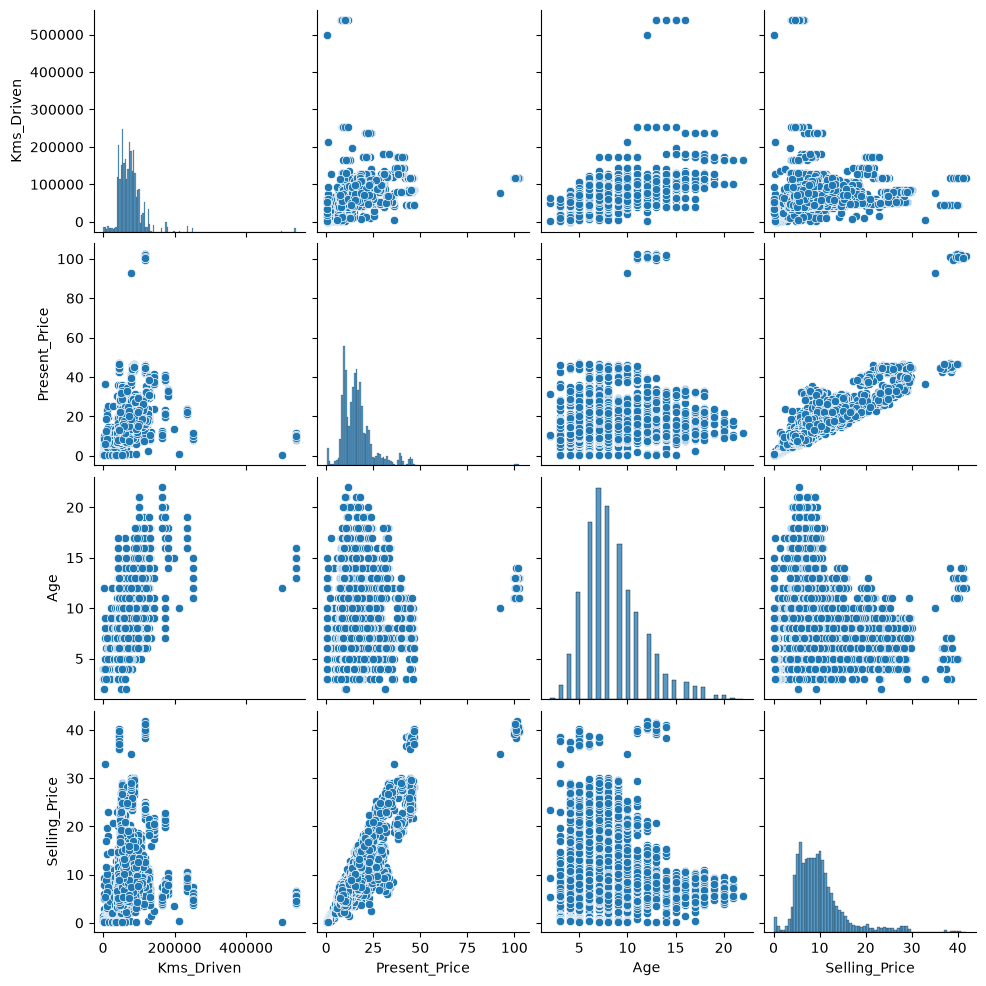

In [8]:
# pairplot des variables quantitatives
sns.pairplot(quant_data)
plt.show()

In [9]:
# Fonction permettant de visualiser les boxplots
def boxplot_func(col):
    fig = px.box(df,x = col)
    fig.show()

In [10]:
# Appliquer la fonctions boxplot_func
for col in quant_data.columns:
  boxplot_func(col)

In [11]:
# Afficher la matrice de corrélation
quant_data.corr()

,Kms_Driven,Present_Price,Age,Selling_Price
Kms_Driven,1.000000,0.249279,0.527629,0.065816
Present_Price,0.249279,1.000000,0.073940,0.870457
Age,0.527629,0.073940,1.000000,-0.188531
Selling_Price,0.065816,0.870457,-0.188531,1.000000


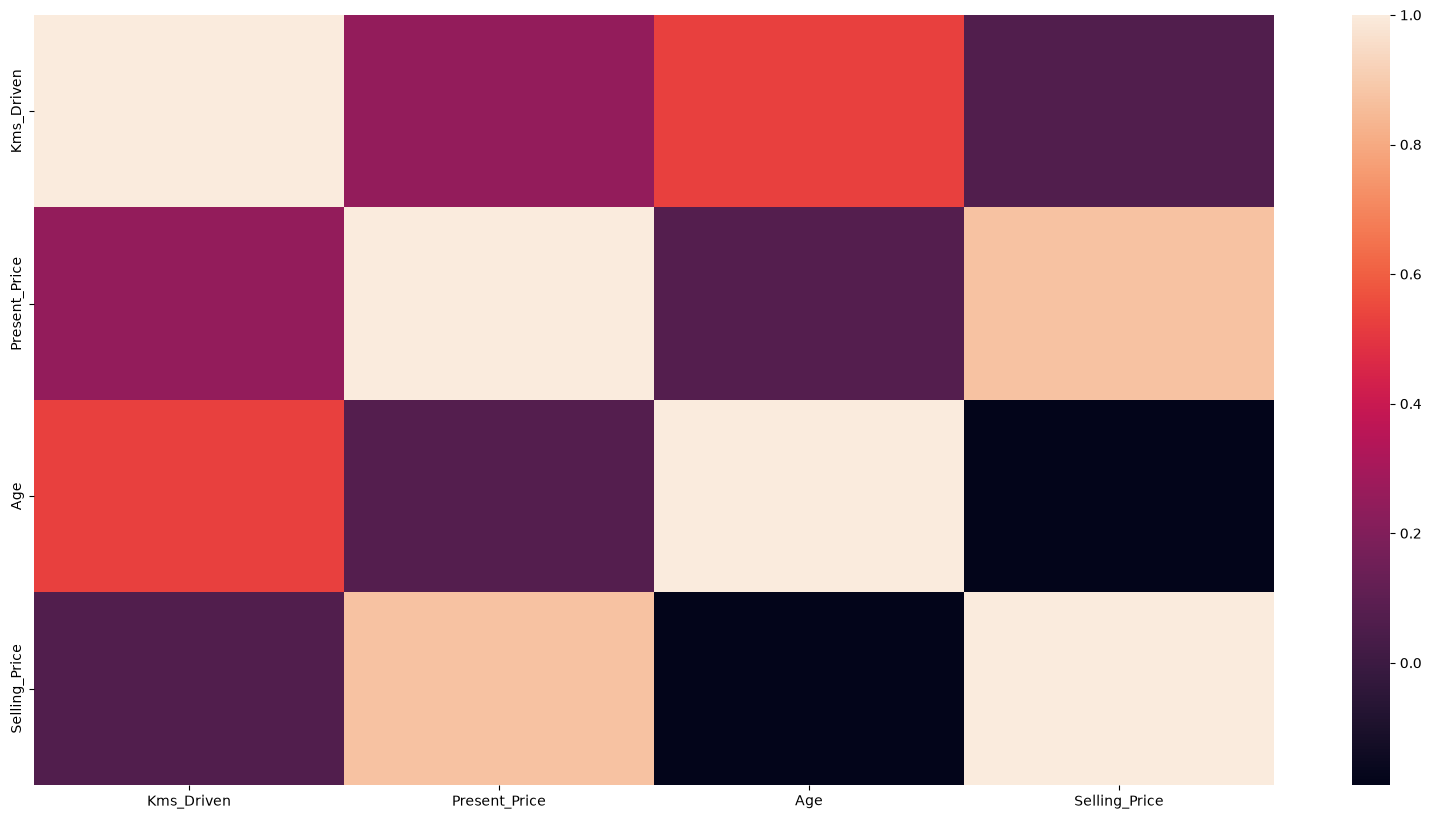

In [12]:
# Visualisaton le matrice de corrélation
plt.figure(figsize = (20, 10))
sns.heatmap(quant_data.corr())
plt.show()

In [13]:
# sélection les variables catégorielles
cat_data = df.select_dtypes(include = 'object')
cat_data.head()

,Fuel_Type,Seller_Type,Transmission
0,Petrol,Dealer,Manual
1,Diesel,Dealer,Manual
2,Petrol,Dealer,Manual
3,Petrol,Dealer,Manual
4,Diesel,Dealer,Manual


In [14]:
# Faire un describre
cat_data.describe()

,Fuel_Type,Seller_Type,Transmission
count,5861,5861,5861
unique,3,2,2
top,Petrol,Dealer,Automatic
freq,2743,3765,3007


In [15]:
# Fonction de visualisaion du counplot
def countplot_func(col):
    val = cat_data[col].value_counts()
    sns.barplot(x = val.index, y = val.values)
    plt.show()

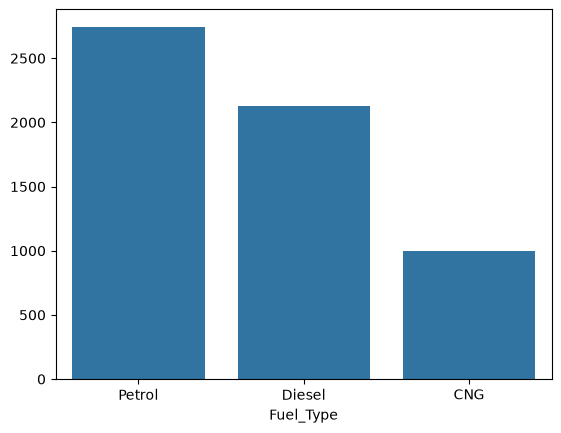

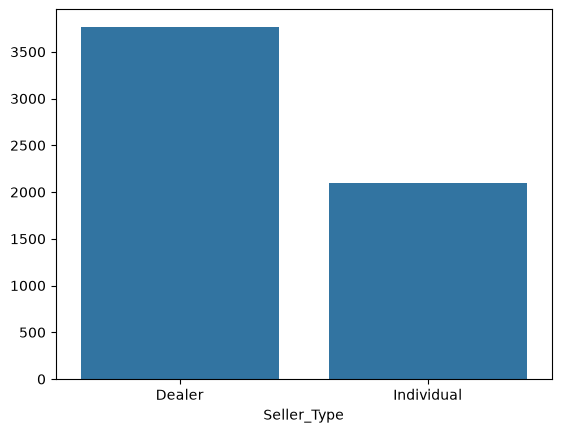

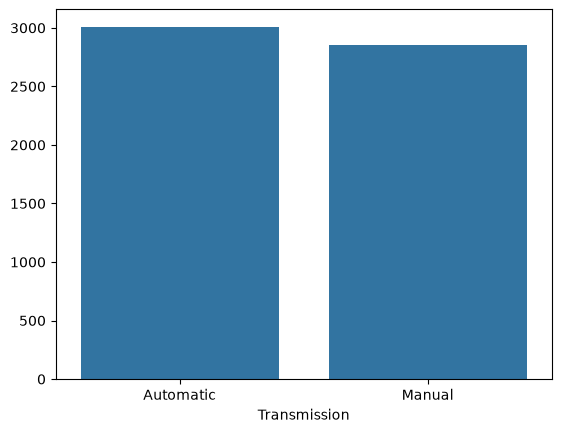

In [16]:
# Appliquer la fonction countplot_func
for col in cat_data.columns:
    countplot_func(col)

In [17]:
# Imputer les valeurs manquantes des variables catégorielle en utilisant le mode
for col in cat_data.columns:
  df.fillna({col: df[col].mode()[0]}, inplace = True)

In [18]:
df.isnull().sum()

Kms_Driven       0
Present_Price    0
Fuel_Type        0
Seller_Type      0
Transmission     0
Age              0
Selling_Price    0
dtype: int64

In [19]:
# Enregistrer les valeurs uniques des variables catégorielles dans un objet joblib
uniques = []
for col in cat_data.columns:
  uniques.append(np.unique(df[col]).tolist())
# sauvegarde
import joblib as jb
jb.dump(uniques, 'uniques.joblib')

['uniques.joblib']

In [20]:
# Encoder les variables catégorielles
from sklearn.preprocessing import LabelEncoder
# Créer différents encodeurs pour les variables catégorielles
encoders = []
for i in range(len(cat_data.columns)):
  encoder = LabelEncoder()
  encoder.fit(df[cat_data.columns[i]]) # le modèle prend le temps de reconnaitre les classes
  df[cat_data.columns[i]] = encoder.transform(df[cat_data.columns[i]]) # encoder les valeurs
  # rajouter l'encoder sur la liste encoders
  encoders.append(encoder)

In [21]:
# afficher
df.head()

,Kms_Driven,Present_Price,Fuel_Type,Seller_Type,Transmission,Age,Selling_Price
0,27000,5.59,2,0,1,6,3.35
1,43000,9.54,1,0,1,7,4.75
2,6900,9.85,2,0,1,3,7.25
3,5200,4.15,2,0,1,9,2.85
4,42450,6.87,1,0,1,6,4.60


In [22]:
import joblib as jb
# sauvegarde les encodeurs
jb.dump(encoders, 'encoders.joblib')

['encoders.joblib']

In [23]:
from sklearn.impute import KNNImputer
# Imputer les valeurs manquantes des variables quantitatives
imputer = KNNImputer(n_neighbors=5)
df[:] = imputer.fit_transform(df)

In [24]:
# fonction d'imputation des valeurs aberrantes
def impute_func(df, col, n_neighbors=5):
    # 2. Détection des outliers (Méthode IQR)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    min_value = Q1 - 1.5 * IQR
    max_value = Q3 + 1.5 * IQR

    # Les valeurs hors bornes deviennent des valeurs manquantes pour le KNNImputer
    df.loc[(df[col] < min_value) | (df[col] > max_value), col] = np.nan # NaN
    # n_neighbors : nombre de voisins pour calculer la moyenne de remplacement
    imputer = KNNImputer(n_neighbors=n_neighbors)
    df[:] = imputer.fit_transform(df)

In [25]:
# Application du traitement
for col in quant_data.columns:
  impute_func(df,col)

In [26]:
# réafficher les boxplots
for col in quant_data.columns:
  boxplot_func(col)

In [27]:
# Fractionner les données
x = df.iloc[:,:-1].values
y = df.iloc[:, -1].values

In [28]:
# importer RobustScaler
from sklearn.preprocessing import RobustScaler
# Normaliser x
scaler = RobustScaler()
scaler.fit(x)
x = scaler.transform(x)

In [29]:
# sauvegarde du scaler
jb.dump(scaler, 'scaler.joblib')

['scaler.joblib']

In [30]:
from sklearn.model_selection import train_test_split
# Splitter les données en train, val et test
x_train, x_vt,y_train,y_vt = train_test_split(x,y , test_size = 0.2, random_state = 42)
# Splitter les données en val et test
x_val, x_test, y_val, y_test = train_test_split(x_vt, y_vt, test_size = 0.5, random_state = 42)

In [31]:
# Afficher les données train
x_train[:5], y_train[:5]

(array([[ 8.39915152e-01,  7.88571968e-01,  1.00000000e+00,
          0.00000000e+00,  0.00000000e+00,  2.50000000e-01],
        [ 1.38309697e+00,  7.27934445e-01,  0.00000000e+00,
          0.00000000e+00,  1.00000000e+00,  1.50000000e+00],
        [ 1.11854545e-01,  1.91947979e-01,  1.00000000e+00,
          0.00000000e+00,  0.00000000e+00, -2.50000000e-01],
        [-1.14545455e-03,  3.51014137e-01,  1.00000000e+00,
          0.00000000e+00,  1.00000000e+00,  2.50000000e-01],
        [ 1.00624242e-01, -6.97646882e-01,  1.00000000e+00,
          0.00000000e+00,  1.00000000e+00,  7.50000000e-01]]),
 array([13.6085135 ,  7.46523384,  8.64629576,  9.33036951,  6.47541033]))

### <font color = 'bisque'>Multiple Linear Regression

In [32]:
# Rechercher les paramètres optimaux de l'algorithme
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.linear_model import LinearRegression

# Validation croisée et figé
cv = KFold(n_splits=5, shuffle=True, random_state=42)
# dictionnaire params
params_lr = {
    'fit_intercept': [True, False], # b = 0 , b # 0
    'positive': [True, False]
 }
# Initialisation du modèle
lr = LinearRegression()
# Initialisation du GridSearchCV
grid_lr = GridSearchCV(lr, params_lr, cv = cv)
# Lancer la recherche
grid_lr.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",LinearRegression()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'fit_intercept': [True, False], 'positive': [True, False]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosi

In [33]:
# Récupérer le modèle optimal en partant de gridsearch
lr_model = grid_lr.best_estimator_

#### <font color = 'teal'> Evaluation du Linear Regression<font>

In [34]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error,root_mean_squared_error
# Calculer le R2 score et Mean Squarred Error
# from math import *
def evaluation(model):
  y_pred = model.predict(x_val)
  r2 = r2_score(y_val, y_pred)
  mse = mean_squared_error(y_val, y_pred)
  mae = mean_absolute_error(y_val, y_pred)
  rmse = root_mean_squared_error(y_val, y_pred)
  return r2, mse, mae, rmse

In [35]:
# Evaluation
r2_lr, mse_lr, mae_lr, rmse_lr = evaluation(lr_model)
print(f"R2 : {r2_lr} -- MSE : {mse_lr} -- RMSE : {rmse_lr} -- MAE : {mae_lr}")

R2 : 0.6498369115217089 -- MSE : 4.707610202914738 -- RMSE : 2.1697027913782887 -- MAE : 1.6185933422598944


### <font color = 'bisque'>Ridge Regression

In [36]:
# Rechercher les paramètres optimaux de l'algorithme
from sklearn.linear_model import Ridge
# dictionnaire params
params_rr = {
    'fit_intercept': [True, False],
    'positive': [True, False],
    'alpha':np.logspace(-8,8, 100) #
 }
# Initialisation du modèle
rr = Ridge()
# Initialisation du GridSearchCV
grid_rr = GridSearchCV(rr, params_rr, cv = cv)
# Lancer la recherche
grid_rr.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Ridge()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'alpha': array([1.0000...00000000e+08]), 'fit_intercept': [True, False], 'positive': [True, False]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int,

In [37]:
# Récupérer le modèle optimal en partant de gridsearch
rr_model = grid_rr.best_estimator_

#### <font color = 'teal'> Evaluation du Ridge<font>

In [38]:
# Evaluation le modèle
r2_rr, mse_rr, mae_rr, rmse_rr = evaluation(rr_model)
print(f"R2 : {r2_rr} -- MSE : {mse_rr} -- RMSE : {rmse_rr} -- MAE : {mae_rr}")

R2 : 0.6498330538602921 -- MSE : 4.707662065509176 -- RMSE : 2.169714742888838 -- MAE : 1.619705311876729


### <font color = 'bisque'>Decision Tree Regressor<font>

In [39]:
# Recherche des paramètres optimaux du decision tree
from sklearn.tree import DecisionTreeRegressor
# Dictionaire des params
params_dt = {
    'max_depth':np.arange(1,30),
    'criterion':['squared_error', 'absolute_error']
}
# Initialisation du modèle
dt = DecisionTreeRegressor(random_state = 42)
# Initialisation du GridSearchCV
grid_dt = GridSearchCV(dt, params_dt, cv = cv)
# Lancer la recherche
grid_dt.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['squared_error', 'absolute_error'], 'max_depth': array([ 1, 2..., 27, 28, 29])}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verb

In [40]:
# Récupérer le modèle optimal en partant de gridsearch
dt_model = grid_dt.best_estimator_

#### <font color = 'teal'> Evaluation du Decision Tree Regressor<font>

In [41]:
# Evaluation le modèle
r2_dt, mse_dt, mae_dt, rmse_dt = evaluation(dt_model)
print(f"R2 : {r2_dt} -- MSE : {mse_dt} -- RMSE : {rmse_dt} -- MAE : {mae_dt}")

R2 : 0.8338000152590459 -- MSE : 2.2344009681057395 -- RMSE : 1.4947912791108127 -- MAE : 1.1037894761437956


### <font color = 'bisque'>Random Forest Regressor<font>

In [42]:
from sklearn.ensemble import RandomForestRegressor

# Dictionnaires des paramètres
params_rf = {
    'n_estimators':np.arange(10,100,10),
    'max_depth':np.arange(1,15)
}
# Initialisation du modèle
rf =  RandomForestRegressor()
# Objet grid
grid_rf = GridSearchCV(rf, params_rf, cv=cv)
# Lancer la recherche
grid_rf.fit(x_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestRegressor()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': array([ 1, 2..., 12, 13, 14]), 'n_estimators': array([10, 20..., 70, 80, 90])}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbo

In [43]:
# Récupérer le modèle optimal en partant de gridsearch
rf_model = grid_rf.best_estimator_

#### <font color = 'teal'> Evaluation du Random Forest<font>

In [44]:
# Evaluation le modèle
r2_rf, mse_rf, mae_rf, rmse_rf = evaluation(rf_model)
print(f"R2 : {r2_rf} -- MSE : {mse_rf} -- RMSE : {rmse_rf} -- MAE : {mae_rf}")

R2 : 0.8806034581142921 -- MSE : 1.6051731243761351 -- RMSE : 1.2669542708306938 -- MAE : 0.954292377161154


In [45]:
# comparaison des métriques
list_names = ['LR', 'RR', 'DT', 'RF']
list_r2 = [r2_lr, r2_rr, r2_dt, r2_rf]
list_mse = [mse_lr, mse_rr, mse_dt, mse_rf]
list_rmse = [rmse_lr, rmse_rr, rmse_dt, rmse_rf]
list_mae = [mae_lr, mae_rr, mae_dt, mae_rf]
list_final = [list_r2, list_mse, list_rmse, list_mae]
for i in range(4):
  fig = px.bar(y = list_names, x = list_final[i], color = list_names, text_auto = True)
  fig.show()

In [46]:
# télécharger le modèle le plus performant
jb.dump(rf_model, 'rf_model.joblib')

['rf_model.joblib']

### <font color = 'bisque'>Tester le modèle le plus performant<font>

In [47]:
#  echantillon des données test
x_test_10 = x_test[:10]
y_test_10 = y_test[:10]
# Prédictions
y_pred_10 = rf_model.predict(x_test_10)
# Parcourir les prédictions
for i in range(10):
  print(f"Prédiction {i + 1} : {y_pred_10[i]:.2f} --Réel :{y_test_10[i]:.2f}")

Prédiction 1 : 12.57 --Réel :12.51
Prédiction 2 : 5.33 --Réel :7.25
Prédiction 3 : 12.12 --Réel :8.38
Prédiction 4 : 6.52 --Réel :5.59
Prédiction 5 : 7.39 --Réel :7.61
Prédiction 6 : 8.43 --Réel :8.39
Prédiction 7 : 5.41 --Réel :4.93
Prédiction 8 : 5.37 --Réel :4.79
Prédiction 9 : 4.98 --Réel :4.65
Prédiction 10 : 8.88 --Réel :8.96
